# Notebook 1 · Converser et se souvenir

*Formation « Comprendre et développer des agents IA spécialisés », module 1.*

**Djassa** est une boutique en ligne d'articles du quotidien : smartphones, écouteurs, baskets, vêtements, sacs. Elle veut une conseillère virtuelle, **Awa**, qui discute avec les clients **et se souvient d'eux** : si Aïcha dit qu'elle chausse du 40, elle ne veut pas le répéter à chaque message, ni la semaine suivante.

<p align="center"><img src="assets/diagrams/nb1_histoire_aicha.png" alt="Deux échelles de mémoire : dans la même conversation, puis la semaine suivante. Sans mémoire, Awa redemande ou répond de façon générique ; avec mémoire, elle se souvient de la pointure 40 et du budget d'Aïcha" width="1000"></p>

Dans ce notebook, on découvre comment fonctionne un **LLM**, puis on lui donne une **mémoire**. Chaque notion est d'abord montrée **en Python pur**, puis **avec LangChain ou LangGraph**.

Exécute les cellules dans l'ordre (`Maj + Entrée`). Tout est dans ce notebook.

---
## Étape 0 · Configuration

**Objectif** : se connecter à OpenAI.

La clé API se met dans un fichier `.env` à la racine du dossier : `OPENAI_API_KEY=sk-...`

On utilise **`gpt-4.1-mini`** : il est rapide, il permet de régler la **température** et de voir les **probabilités** des tokens, deux notions explorées plus loin.

In [1]:
import os, math
from dotenv import load_dotenv
from openai import OpenAI

load_dotenv()
assert os.getenv("OPENAI_API_KEY"), "Ajoute OPENAI_API_KEY=sk-... dans le fichier .env, puis redémarre le noyau"

client = OpenAI()
MODELE = "gpt-4.1-mini"
print(f"Connecté à OpenAI : {MODELE}")

Connecté à OpenAI : gpt-4.1-mini


---
## Étape 1 · Un LLM lit des tokens, pas des mots

**Objectif** : voir comment un LLM « lit » un texte.

Un LLM découpe d'abord le texte en **tokens** : un mot entier, un bout de mot, un espace, un symbole.

In [2]:
import tiktoken
encodeur = tiktoken.get_encoding("o200k_base")       # le découpage des modèles GPT-4o, 4.1 et 5

texte = "Les Nike Air Force 1 blanches sont à 75 000 FCFA chez Djassa."
tokens = encodeur.encode(texte)

print(f"{len(texte)} caractères → {len(tokens)} tokens\n")
print(" | ".join(encodeur.decode([t]) for t in tokens))

61 caractères → 20 tokens

Les |  Nike |  Air |  Force |   | 1 |  bl | anches |  sont |  à |   | 75 |   | 000 |  FC | FA |  chez |  Dj | assa | .


Voici le même résultat, étape par étape : le texte devient une suite de tokens, puis une suite de nombres.

<p align="center"><img src="assets/diagrams/nb1_lecture_tokens.png" alt="Le texte « Les Nike Air Force 1 blanches sont à 75 000 FCFA chez Djassa. » est découpé en 20 tokens, chacun converti en numéro, puis transmis au LLM" width="960"></p>

Les mots courants forment **un seul token**, alors que les mots rares ou les noms de marque sont **coupés en morceaux**.

Comparons quelques phrases :

In [3]:
phrases = ["Bonjour, je cherche des baskets.",
           "Hello, I am looking for sneakers.",
           "anticonstitutionnellement",
           "😍👟🔥"]
for phrase in phrases:
    print(f"{len(encodeur.encode(phrase)):>3} tokens │ {phrase}")

  7 tokens │ Bonjour, je cherche des baskets.
  8 tokens │ Hello, I am looking for sneakers.
  5 tokens │ anticonstitutionnellement
  4 tokens │ 😍👟🔥


**À retenir**
- Un LLM lit des **tokens**. Ordre de grandeur : 1 token ≈ ¾ de mot en anglais courant. En français, c'est variable et souvent un peu plus.
- Le français coûte un peu plus de tokens que l'anglais, et les emojis sont coûteux.
- Les tokens sont l'**unité de coût** (on paie à l'envoi comme à la réception) et de **limite** (un LLM ne lit qu'un nombre limité de tokens à la fois).

## Étape 2 · Il prédit le token suivant

**Objectif** : comprendre comment un LLM « écrit ».

Un LLM ne « réfléchit » pas comme nous : il calcule **quel token a le plus de chances de venir ensuite**, l'ajoute, puis recommence, token après token.

**Ce processus est appelé génération autorégressive** : le LLM utilise les tokens déjà présents dans le texte, y compris ceux qu'il vient de générer, pour prédire le suivant.

<p align="center"><img src="assets/diagrams/nb1_generation_token.png" alt="Un LLM écrit token par token : découpage du texte, probabilités des candidats, choix, puis on recommence" width="920"></p>

On peut demander à OpenAI de nous montrer ces **probabilités** :

In [4]:
reponse = client.chat.completions.create(
    model=MODELE,
    messages=[{"role": "system", "content": "Continue la phrase. Écris uniquement le mot suivant."},
              {"role": "user", "content": "Pour aller courir, j'achète une paire de"}],
    max_tokens=1, logprobs=True, top_logprobs=5, temperature=0,
)
for candidat in reponse.choices[0].logprobs.content[0].top_logprobs:
    proba = math.exp(candidat.logprob)                # logprob -> probabilité entre 0 et 1
    print(f"{candidat.token!r:<14} {'█' * round(proba * 40):<40} {proba:.0%}")

'cha'          █████████████████████████████            73%
'b'            ███████████                              27%
'chaus'                                                 0%
' chaussures'                                           0%
'basket'                                                0%


Le LLM hésite entre `'cha'` (le début de **cha**ussures) et `'b'` (le début de **b**askets). Il ne choisit pas un mot, il choisit un **token**.

**Attention** : Ces probabilités valent **pour ce contexte précis** (cette consigne, cette phrase), et on ne voit que les 5 premiers candidats parmi des dizaines de milliers.

### La température : prudent ou créatif ?

La **température** règle la façon de choisir parmi ces candidats :
- **0** : on prend le plus probable. C'est stable et presque répétable (OpenAI ne garantit pas un résultat strictement identique à chaque appel), idéal pour une réponse de SAV.
- **1 ou plus** : on tire au sort, et les candidats moins probables ont leur chance. C'est créatif et varié, idéal pour du marketing.

Demandons 3 slogans publicitaires avec chaque réglage :

In [5]:
consigne = "Écris un slogan de 8 mots maximum pour le hoodie Adidas vendu par Djassa."

for temperature in (0, 1.3):
    print(f"\nTempérature {temperature}")
    for _ in range(3):
        r = client.chat.completions.create(model=MODELE, temperature=temperature,
                                           messages=[{"role": "user", "content": consigne}])
        print("   •", r.choices[0].message.content)


Température 0


   • Confort Adidas, style Djassa – porte ta différence.


   • Confort Adidas, style Djassa – porte ta différence.


   • Confort Adidas, style Djassa – porte ta différence.

Température 1.3


   • Confort ultime, style assuré – Adidas by Djassa.


   • Stylé, confortable, unique – le hoodie Adidas Djassa.


   • Style unique, confort total – Adidas par Djassa.


**À retenir**
- Un LLM écrit **token par token**, en choisissant parmi les plus probables.
- **Température basse** = réponses stables (SAV, données). **Température haute** = réponses variées (slogans, idées).
- **À savoir** : Sur certains modèles « de raisonnement » (par exemple `gpt-5-mini`, en octobre 2026), la température n'est pas réglable. Ces options évoluent : vérifie la documentation du modèle choisi.

---
## Étape 3 · Parler à un LLM : les rôles

**Objectif** : donner une personnalité à Awa.

On envoie au LLM une **liste de messages**, chacun avec un **rôle** : `system` (le développeur), `user` (le client) ou `assistant` (le LLM).

<p align="center"><img src="assets/diagrams/nb1_roles_messages.png" alt="Liste de messages system et user envoyée au LLM, qui répond avec un message assistant" width="760"></p>

Le **prompt système** est invisible pour le client, mais il guide toutes les réponses.

In [6]:
SYSTEME = """Tu es Awa, conseillère de vente de Djassa, boutique en ligne ivoirienne d'articles du quotidien
(smartphones, écouteurs, baskets, vêtements, sacs), qui livre en Côte d'Ivoire. Tu n'as pas accès au catalogue : n'invente ni prix, ni stock, ni délai de livraison.
Tu vouvoies toujours le client. Réponds en français, en 3 phrases maximum, avec un ton chaleureux."""

messages = [{"role": "system", "content": SYSTEME},
            {"role": "user", "content": "Bonjour ! Vous pouvez m'aider à choisir un cadeau ?"}]

reponse = client.chat.completions.create(model=MODELE, messages=messages)
print("Awa :", reponse.choices[0].message.content)
print(f"\n{reponse.usage.prompt_tokens} tokens envoyés, {reponse.usage.completion_tokens} tokens reçus")

Awa : Bonjour ! Bien sûr, je serais ravie de vous aider à choisir un cadeau. Pourriez-vous me dire à qui est destiné ce cadeau et quel type d'article vous intéresse ?

115 tokens envoyés, 37 tokens reçus


### Avec LangChain

LangChain propose une interface **identique pour tous les fournisseurs** (OpenAI, Anthropic, Mistral, Ollama...). Pour changer de fournisseur, tu changes une seule ligne.

In [7]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model=MODELE)
reponse = llm.invoke([("system", SYSTEME), ("user", "Bonjour ! Vous pouvez m'aider à choisir un cadeau ?")])
print("Awa :", reponse.content)

Awa : Bonjour ! Avec plaisir, quel type de cadeau recherchez-vous et pour quelle occasion ? Je suis là pour vous guider parmi nos articles du quotidien.


**À retenir**
- On parle à un LLM avec une **liste de messages** : `system`, `user`, `assistant`.
- Le **prompt système** définit la personnalité et les règles d'Awa.

---
## Étape 4 · Le problème : un LLM n'a pas de mémoire

**Objectif** : constater que chaque appel repart de zéro.

Aïcha se présente, puis pose une deuxième question **dans un appel séparé** :

In [8]:
def demander(question):
    """Un appel isolé : on n'envoie QUE le prompt système et la question."""
    r = client.chat.completions.create(model=MODELE, messages=[{"role": "system", "content": SYSTEME},
                                                              {"role": "user", "content": question}])
    return r.choices[0].message.content

for question in ["Bonjour, je m'appelle Aïcha et je chausse du 40.", "Vous vous souvenez de ma pointure ?"]:
    print(f"Aïcha : {question}\nAwa   : {demander(question)}\n")

Aïcha : Bonjour, je m'appelle Aïcha et je chausse du 40.
Awa   : Bonjour Aïcha, je suis ravie de faire votre connaissance ! Pourriez-vous me dire quel type d'articles vous intéresse aujourd'hui, baskets ou autres ? Je suis là pour vous aider à trouver ce qu'il vous faut.



Aïcha : Vous vous souvenez de ma pointure ?
Awa   : Bonjour ! Je n’ai malheureusement pas accès à vos informations personnelles comme votre pointure. Pourriez-vous me la rappeler afin que je puisse mieux vous conseiller ?



**Awa a déjà oublié !** Un LLM est **sans état** : il ne garde rien d'un appel à l'autre. Le modèle ne reçoit que **les messages que ton programme lui transmet lors de cet appel**. Rien d'autre.

### Le schéma à garder en tête pour la suite

<p align="center"><img src="assets/diagrams/nb1_architecture_memoire.png" alt="Le client parle à l'application, qui stocke la mémoire hors du LLM et envoie un contexte choisi au LLM" width="860"></p>


  La mémoire n'est **pas dans le LLM**. C'est **l'application** (ton code) qui la stocke, la relit, et choisit quoi envoyer au modèle.

---
## Étape 5 · Donner une mémoire : l'historique

**Objectif** : faire en sorte qu'Awa se souvienne de la conversation.

L'astuce est simple : **à chaque message, on renvoie toute la conversation**.

```
Appel 1 : [système] [Aïcha : je chausse du 40]
Appel 2 : [système] [Aïcha : je chausse du 40] [Awa : ...] [Aïcha : ma pointure ?]
```

<p align="center"><img src="assets/diagrams/nb1_historique_messages.png" alt="Trois appels successifs : chaque appel renvoie toute la conversation, et le nombre de tokens envoyés passe de 120 à 180 puis 248" width="860"></p>

### En Python pur : une liste qu'on remplit

In [9]:
historique = [{"role": "system", "content": SYSTEME}]
tokens_envoyes = []                                                          # pour la courbe de l'étape 6

def discuter(message_client):
    historique.append({"role": "user", "content": message_client})          # 1. on ajoute le message
    r = client.chat.completions.create(model=MODELE, messages=historique)    # 2. on envoie TOUT l'historique
    reponse = r.choices[0].message.content
    historique.append({"role": "assistant", "content": reponse})             # 3. on garde la réponse
    tokens_envoyes.append(r.usage.prompt_tokens)
    print(f"Client : {message_client}\nAwa : {reponse}\n   {r.usage.prompt_tokens} tokens envoyés\n")

discuter("Bonjour, je m'appelle Aïcha et je chausse du 40.")
discuter("Vous vous souvenez de ma pointure ?")

Client : Bonjour, je m'appelle Aïcha et je chausse du 40.
Awa : Bonjour Aïcha, ravie de faire votre connaissance ! Pourriez-vous me préciser quel type de chaussures vous intéresse afin que je puisse mieux vous conseiller ? N’hésitez pas à me dire ce que vous cherchez !
   120 tokens envoyés



Client : Vous vous souvenez de ma pointure ?
Awa : Bonjour Aïcha, oui bien sûr, vous m’avez dit que vous chaussez du 40. Souhaitez-vous que je vous aide à trouver des baskets, ou un autre type de chaussures ? Je suis à votre disposition !
   180 tokens envoyés



Awa se souvient. Remarque le compteur de tokens : **il augmente**, car on renvoie tout à chaque fois. On y revient à l'étape 6.

### Avec LangGraph : une mémoire par client

Une vraie boutique a **des centaines de clients en même temps**. Il faut un historique **par client**.

LangGraph gère ça avec un **checkpointer** : il range chaque conversation dans un « dossier » identifié par un `thread_id`.

In [10]:
from langgraph.graph import StateGraph, MessagesState, START
from langgraph.checkpoint.memory import InMemorySaver

def noeud_lea(etat):
    """Awa lit l'historique de la conversation et répond."""
    return {"messages": [llm.invoke([("system", SYSTEME)] + etat["messages"])]}

graphe = StateGraph(MessagesState)          # l'état = la liste des messages
graphe.add_node("lea", noeud_lea)
graphe.add_edge(START, "lea")
lea = graphe.compile(checkpointer=InMemorySaver())     # le checkpointer = la mémoire, rangée par client

In [11]:
def parler(client_id, message):
    config = {"configurable": {"thread_id": client_id}}       # le « dossier » de ce client
    etat = lea.invoke({"messages": [("user", message)]}, config)
    print(f"{client_id} : {message}\nAwa : {etat['messages'][-1].content}\n")

parler("aicha", "Bonjour, je m'appelle Aïcha et je chausse du 40.")
parler("yao", "Salut, moi c'est Yao, je fais du 44.")
parler("aicha", "Vous vous souvenez de ma pointure ?")

aicha : Bonjour, je m'appelle Aïcha et je chausse du 40.
Awa : Bonjour Aïcha, ravie de faire votre connaissance ! Je serais heureuse de vous aider à trouver des baskets ou tout autre article à votre taille. N’hésitez pas à me préciser ce que vous recherchez exactement.



yao : Salut, moi c'est Yao, je fais du 44.
Awa : Bonjour Yao, ravi de vous rencontrer ! Pour les baskets en taille 44, puis-je vous aider à trouver un modèle spécifique ou une marque particulière ? N’hésitez pas à me dire ce que vous cherchez.



aicha : Vous vous souvenez de ma pointure ?
Awa : Bonjour Aïcha, oui bien sûr, vous chaussez du 40 ! Dites-moi simplement quel type de baskets ou d'articles vous souhaitez découvrir, je suis à votre service.



Awa ne mélange pas Aïcha et Yao : chaque `thread_id` a **sa propre mémoire**.

**À retenir**
- La mémoire d'une conversation, c'est **l'historique qu'on renvoie** à chaque appel.
- Avec LangGraph, le **checkpointer** stocke un historique **par conversation** (`thread_id`). En production, on le branche sur une base de données (SQLite, Postgres...).

---
## Étape 6 · La mémoire coûte cher

**Objectif** : voir les limites de l'historique, et deux solutions.

Continuons la conversation avec Aïcha, et observons le compteur de tokens :

In [12]:
discuter("Je cherche des baskets blanches pour aller avec un jean.")
discuter("Mon budget est de 80 000 FCFA maximum.")
discuter("Je les mettrai surtout pour aller travailler à Cocody.")
discuter("Et pour ma sœur, une idée de cadeau à moins de 20 000 FCFA ? Elle adore le sport.")

Client : Je cherche des baskets blanches pour aller avec un jean.
Awa : Parfait, Aïcha ! Les baskets blanches s’accordent très bien avec un jean pour un style décontracté et élégant. Voulez-vous que je vous oriente vers des modèles classiques ou plutôt tendance ?
   248 tokens envoyés



Client : Mon budget est de 80 000 FCFA maximum.
Awa : Merci pour cette précision, Aïcha ! Je vous recommande de jeter un œil à notre sélection de baskets blanches dans cette gamme de prix. Souhaitez-vous que je vous aide à trouver des modèles spécifiques correspondant à votre budget ?
   312 tokens envoyés



Client : Je les mettrai surtout pour aller travailler à Cocody.
Awa : Très bien, Aïcha ! Pour un usage professionnel à Cocody, je vous conseille des baskets blanches à la fois confortables et élégantes. Préférez-vous un style sobre ou un modèle avec quelques détails tendances pour apporter une touche d’originalité ?
   381 tokens envoyés



Client : Et pour ma sœur, une idée de cadeau à moins de 20 000 FCFA ? Elle adore le sport.
Awa : C’est une belle attention, Aïcha ! Pour une passionnée de sport, un accessoire comme une paire d’écouteurs ou un sac de sport léger pourrait lui plaire. Souhaitez-vous que je vous propose des options dans cette fourchette de prix ?
   467 tokens envoyés



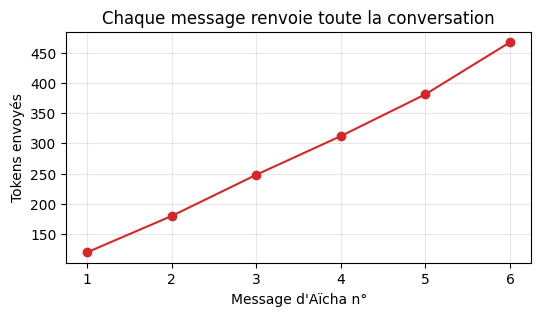

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 3))
plt.plot(range(1, len(tokens_envoyes) + 1), tokens_envoyes, marker="o", color="tab:red")
plt.title("Chaque message renvoie toute la conversation")
plt.xlabel("Message d'Aïcha n°"); plt.ylabel("Tokens envoyés"); plt.grid(alpha=0.3)
plt.show()

**La courbe monte à chaque message** : on renvoie toute la conversation. Avec 50 échanges, chaque question envoie environ 50 fois plus de tokens que la première.
**À savoir** : Le *cache de prompt* d'OpenAI peut faire baisser le prix de la partie déjà envoyée (selon le modèle et la requête), mais le volume, lui, grandit toujours.
Et même si les modèles récents acceptent des centaines de milliers de tokens, un historique trop long **ralentit** les réponses et **noie** les informations importantes.

### Solution 1 : la fenêtre glissante

On ne garde que les **N derniers messages**. C'est simple et le coût est fixe... mais Awa **oublie le début**. Regardons ce que le modèle reçoit vraiment :

**À toi de prédire.** La fenêtre glissante ci-dessous ne garde que les **2 derniers messages**, plus le prompt système. Aïcha demande ensuite : « Rappelez-moi ma pointure ? » Avant d'exécuter la cellule, décide : Awa va-t-elle répondre « 40 » ?

<details>
<summary>Voir la réponse</summary>

Non, elle ne peut pas. Le « 40 » date du **tout premier message**, qui n'est plus dans la fenêtre : le modèle ne reçoit que ce que ton code lui envoie. Elle redemande la pointure, ou pire, elle en devine une. Vérifie dans la cellule : la liste « Ce que le modèle reçoit » ne contient pas le message d'Aïcha sur sa pointure.

</details>

In [14]:
def fenetre_glissante(messages, n=2):
    """Garde le prompt système + les n derniers messages."""
    return [messages[0]] + messages[1:][-n:]

question = {"role": "user", "content": "Rappelez-moi ma pointure ?"}
courte = fenetre_glissante(historique) + [question]

print("Ce que le modèle reçoit :")
for m in courte:
    print(f"   [{m['role']}] {m['content'][:80]}...".replace("\n", " "))

r = client.chat.completions.create(model=MODELE, messages=courte)
print("\nAwa :", r.choices[0].message.content)

Ce que le modèle reçoit :
   [system] Tu es Awa, conseillère de vente de Djassa, boutique en ligne ivoirienne d'articl...
   [user] Et pour ma sœur, une idée de cadeau à moins de 20 000 FCFA ? Elle adore le sport...
   [assistant] C’est une belle attention, Aïcha ! Pour une passionnée de sport, un accessoire c...
   [user] Rappelez-moi ma pointure ?...



Awa : Je suis ravie de vous aider, mais je n’ai pas accès à vos informations personnelles comme votre pointure. Pourriez-vous me la rappeler, s’il vous plaît ?


Le « 40 » n'est plus dans ce que le modèle reçoit : Awa **ne peut pas** le connaître. Elle redemande (ou, pire, elle devine).

### Solution 2 : le résumé

On demande au LLM de **résumer** les anciens messages en quelques lignes, puis on remplace l'historique par ce résumé et les derniers messages. Awa garde l'essentiel, pour beaucoup moins de tokens :

In [15]:
def resumer(messages):
    """Demande au LLM un résumé court de la conversation, centré sur le client."""
    texte = "\n".join(f"{m['role']} : {m['content']}" for m in messages[1:])
    r = client.chat.completions.create(model=MODELE, messages=[{"role": "user", "content":
        "Résume cette conversation de vente en 3 lignes. Garde les infos sur le client "
        "(prénom, tailles, goûts, budget) :\n\n" + texte}])
    return r.choices[0].message.content

resume = resumer(historique)
print("Résumé :", resume)

Résumé : Aïcha chausse du 40 et cherche des baskets blanches confortables et élégantes pour aller travailler à Cocody, avec un budget maximum de 80 000 FCFA. Elle préfère un style adapté au jean, pouvant être sobre ou avec quelques détails tendances. Elle souhaite également des idées de cadeau à moins de 20 000 FCFA pour sa sœur sportive.


In [16]:
compacte = [historique[0], {"role": "system", "content": f"Résumé de la conversation : {resume}"},
            *historique[-2:], question]
r = client.chat.completions.create(model=MODELE, messages=compacte)
print("Awa :", r.choices[0].message.content)

Awa : Vous m'avez indiqué que vous chaussez du 40, Aïcha. Souhaitez-vous que je vous suggère des baskets blanches confortables dans cette taille ?


### Le même message, trois stratégies

<p align="center"><img src="assets/diagrams/nb1_trois_strategies.png" alt="Trois stratégies pour la même question : l'historique complet connaît la pointure, la fenêtre glissante l'a oubliée, le résumé la garde pour moins de tokens" width="860"></p>

On compte les tokens **du même texte** avec `tiktoken` pour comparer à armes égales :

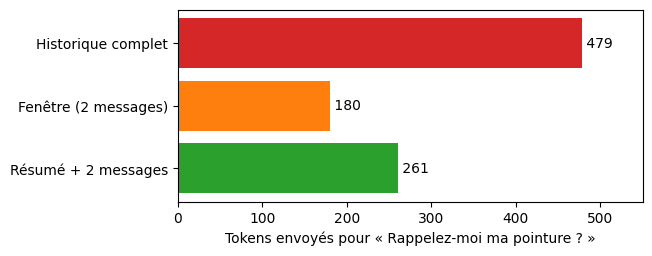

Historique complet : 479 tokens | Fenêtre (2 messages) : 180 tokens | Résumé + 2 messages : 261 tokens
L'API annonce 284 tokens pour le résumé : elle ajoute quelques tokens de mise en forme par message.


In [17]:
def compter(messages):
    return sum(len(encodeur.encode(m["content"])) for m in messages)

strategies = {"Historique complet": historique + [question],
              "Fenêtre (2 messages)": courte,
              "Résumé + 2 messages": compacte}
tailles = {nom: compter(msgs) for nom, msgs in strategies.items()}

plt.figure(figsize=(6, 2.5))
plt.barh(list(tailles), list(tailles.values()), color=["tab:red", "tab:orange", "tab:green"])
for i, t in enumerate(tailles.values()):
    plt.text(t, i, f" {t}", va="center")
plt.xlim(0, max(tailles.values()) * 1.15); plt.gca().invert_yaxis(); plt.xlabel("Tokens envoyés pour « Rappelez-moi ma pointure ? »")
plt.show()
print(" | ".join(f"{nom} : {t} tokens" for nom, t in tailles.items()))
print(f"L'API annonce {r.usage.prompt_tokens} tokens pour le résumé : elle ajoute quelques tokens de mise en forme par message.")

**À retenir**

| Stratégie | Avantage | Inconvénient |
|---|---|---|
| Historique complet | Rien n'est perdu | Coût et lenteur qui augmentent |
| Fenêtre glissante | Simple, coût fixe | Oublie le début (ici, la pointure) |
| Résumé | Garde l'essentiel, peu de tokens | Un appel en plus, des détails perdus |

En pratique, on **combine** souvent : un résumé des anciens messages + les derniers messages en entier.

---
## Étape 7 · La mémoire long terme : un profil client

**Objectif** : qu'Awa se souvienne d'Aïcha **la semaine prochaine**, dans une nouvelle conversation.

L'historique et le résumé sont du **texte libre**. Pour une mémoire durable, on préfère une **fiche client structurée**, comme dans un logiciel de gestion client (CRM) : prénom, pointure, budget...

**Piège** : « je cherche des baskets blanches » ne veut pas dire « j'adore le blanc », et « ma sœur adore le sport » parle de la sœur, pas d'Aïcha. Une bonne mémoire distingue ce que le client **a dit** de ce qu'on **suppose** : d'où une case `a_confirmer`.

Le LLM va **remplir cette fiche** à partir de la conversation. **Pydantic**, la bibliothèque Python de référence pour décrire et **valider** des données, garantit le format.

In [18]:
from pydantic import BaseModel, Field

class ProfilClient(BaseModel):
    """La fiche client qu'Awa garde en mémoire d'une visite à l'autre."""
    prenom: str | None = Field(description="Prénom du client")
    pointure: int | None = Field(description="Pointure de chaussures du client")
    budget_max: int | None = Field(description="Budget maximum en FCFA (nombre entier)")
    gouts: list[str] = Field(description="Goûts durables affirmés par le client (« j'adore le bleu »), pas ceux de ses proches")
    a_confirmer: list[str] = Field(description="Goûts supposés, cités pour un seul achat (ex. la couleur des baskets cherchées)")

### En Python pur : les « sorties structurées » d'OpenAI

`client.chat.completions.parse()` oblige le LLM à répondre **exactement** au format de la classe. Pydantic vérifie ensuite les types : la pointure est bien un **nombre entier**, les couleurs une **liste**...

In [19]:
messages_client = "\n".join(m["content"] for m in historique if m["role"] == "user")
CONSIGNE = ("Remplis la fiche du client à partir de ses messages. N'invente rien. "
            "Un goût cité pour un seul achat va dans a_confirmer, pas dans gouts.")

r = client.chat.completions.parse(
    model=MODELE, temperature=0,
    response_format=ProfilClient,                    # le format imposé
    messages=[{"role": "system", "content": CONSIGNE},
              {"role": "user", "content": messages_client}],
)
profil = r.choices[0].message.parsed                 # un vrai objet Python, déjà validé
print(profil.model_dump_json(indent=2))
print("\nPointure + 1 =", profil.pointure + 1, "(c'est bien un nombre)")

{
  "prenom": "Aïcha",
  "pointure": 40,
  "budget_max": 80000,
  "gouts": [],
  "a_confirmer": [
    "baskets blanches"
  ]
}

Pointure + 1 = 41 (c'est bien un nombre)


Et si la donnée a une mauvaise forme ? Pydantic la **refuse** :

In [20]:
from pydantic import ValidationError

try:
    ProfilClient(prenom="Aïcha", pointure="grande", budget_max=None, gouts=[], a_confirmer=[])
except ValidationError as erreur:
    print("Fiche refusée :", erreur.errors()[0]["loc"][0], "→", erreur.errors()[0]["msg"])

Fiche refusée : pointure → Input should be a valid integer, unable to parse string as an integer


**Attention** : Pydantic garantit la **forme** (une pointure est un nombre), **pas la vérité** : si le LLM attribue à Aïcha le goût de sa sœur, la fiche reste « valide ».
D'où la case `a_confirmer` et la règle : **en cas de doute, on demande au client**.

### Avec LangChain

`with_structured_output()` fait la même chose, quel que soit le fournisseur de LLM.

In [21]:
extracteur = llm.with_structured_output(ProfilClient)
profil_lc = extracteur.invoke(f"{CONSIGNE}\n\n{messages_client}")
print(profil_lc)

prenom='Aïcha' pointure=40 budget_max=80000 gouts=[] a_confirmer=['blanc']


### Une semaine plus tard...

Aïcha revient. C'est une **nouvelle conversation** : l'historique est vide. Mais on glisse sa fiche dans le prompt système, avec une consigne : **faire confirmer** ce qui est incertain.

In [22]:
def accueillir(fiche):
    """Nouvelle conversation : seule la fiche (si elle existe) sert de mémoire."""
    systeme = SYSTEME
    if fiche:
        systeme += (f"\n\nFiche du client (mémoire long terme) : {fiche.model_dump_json()}"
                    "\nUtilise sans les redemander les informations sûres de la fiche. Avant d'utiliser un point de « a_confirmer », demande au client de le confirmer.")
    r = client.chat.completions.create(model=MODELE, messages=[
        {"role": "system", "content": systeme},
        {"role": "user", "content": "Re-bonjour ! Vous auriez des baskets pour moi ?"}])
    return r.choices[0].message.content

print("Awa :", accueillir(profil))

Awa : Re-bonjour Aïcha ! Souhaitez-vous toujours des baskets blanches en taille 40, comme vous l'aviez mentionné précédemment ? Je peux vous aider à trouver le modèle parfait selon votre budget.


Awa reconnaît Aïcha et adapte son conseil **sans qu'Aïcha ait rien répété**, et elle vérifie ce qui n'était qu'une supposition.

### Le droit à l'oubli

Aïcha demande la suppression de ses données. On efface sa fiche, et Awa ne peut plus personnaliser :

In [23]:
profil = None                                   # en production : supprimer la fiche de la base
print("Awa :", accueillir(profil))

Awa : Bonjour ! Nous avons une belle sélection de baskets, adaptées à différents styles et besoins. Voulez-vous des modèles plutôt sportifs, décontractés ou pour un usage quotidien ?


Le parcours complet, de la conversation à la visite suivante :

<p align="center"><img src="assets/diagrams/nb1_profil_client.png" alt="De la conversation à la fiche client : le LLM remplit la fiche ProfilClient validée par Pydantic, la fiche est relue une semaine plus tard dans le prompt système, et le droit à l'oubli l'efface" width="1000"></p>

**À retenir**
- La **mémoire long terme** se stocke **hors du LLM**, idéalement sous forme **structurée** (une fiche, une base de données).
- **Pydantic** décrit le format attendu et **garantit la forme**, pas la vérité : ce qui est supposé doit être **confirmé** par le client.
- **Attention** : Une fiche client contient des **données personnelles** : en production, il faut respecter la réglementation sur les données personnelles qui s'applique à ta boutique (en Côte d'Ivoire : la loi sur la protection des données à caractère personnel, contrôlée par l'ARTCI ; en Europe : le RGPD) : consentement, durée de conservation, droit à l'oubli comme ci-dessus.

---
## Synthèse : les 4 mémoires d'un assistant

<p align="center"><img src="assets/diagrams/nb1_quatre_memoires.png" alt="Les quatre mémoires d'un assistant classées par durée de vie" width="940"></p>

**Les 3 idées à garder**
1. Un LLM **prédit des tokens** : il ne « sait » rien de ta boutique et ne se souvient de rien.
2. La mémoire, **c'est ton code** qui la gère, et elle a un coût.
3. Pour une mémoire durable et fiable, on **structure** les données (Pydantic).

**Repères**

| Concept | Python pur | Framework |
|---|---|---|
| Appeler un LLM | `client.chat.completions.create()` | `ChatOpenAI().invoke()` (LangChain) |
| Mémoire par conversation | une liste `historique` | `checkpointer` + `thread_id` (LangGraph) |
| Sortie structurée | `client.chat.completions.parse()` | `with_structured_output()` (LangChain) |

**Prochain notebook** : Awa sait parler, mais elle ne connaît pas le stock. Elle va apprendre à **utiliser des outils** (stock, livraison, retours) : c'est le passage de l'assistant à l'**agent**.